# N4　訂單銷售預測（第 6 節）

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/RealKazuya/ai-manufacturing-lab/blob/main/notebooks/N4_sales_forecast.ipynb)

〈AI賦能製造：從工廠數據到AI決策〉課程筆記本。資料全部是教學用虛構（恆準精密工業）。

**用法**：由上往下逐格執行（Shift＋Enter）。要改的參數都在「參數」那一格。

In [ ]:
!pip -q install lightgbm==4.7.0

In [1]:
# ── 環境設定（每次開啟先執行這一格）──
import sys, os
IN_COLAB = "google.colab" in sys.modules
LOCAL_DATA = os.path.join("..", "data")
DATA = LOCAL_DATA if os.path.isdir(LOCAL_DATA) else "https://raw.githubusercontent.com/RealKazuya/ai-manufacturing-lab/main/data/"
def path(p):
    return os.path.join(DATA, p) if DATA == LOCAL_DATA else DATA + p
print("資料來源：", "本機" if DATA == LOCAL_DATA else "GitHub", "｜Colab：", IN_COLAB)

資料來源： 本機 ｜Colab： False


In [2]:
import matplotlib, matplotlib.pyplot as plt
if IN_COLAB:   # Colab 沒有中文字型，下載思源黑體（約 16 MB）
    import urllib.request, matplotlib.font_manager as fm
    f = "/tmp/NotoSansTC.otf"
    if not os.path.exists(f):
        urllib.request.urlretrieve("https://github.com/google/fonts/raw/main/ofl/notosanstc/NotoSansTC%5Bwght%5D.ttf", f)
    fm.fontManager.addfont(f); matplotlib.rcParams["font.family"] = fm.FontProperties(fname=f).get_name()
else:
    matplotlib.rcParams["font.family"] = ["Microsoft JhengHei", "sans-serif"]
matplotlib.rcParams["axes.unicode_minus"] = False

## 參數

三位自願者的手繪預測（2025 年 1～6 月，AH 系列合計件數）。

In [3]:
HAND = {"自願者 1": [1550, 1500, 1650, 1600, 1650, 1600],
        "自願者 2": [1600, 1350, 1700, 1650, 1700, 1650],
        "自願者 3": [1500, 1450, 1600, 1550, 1600, 1550]}

## 讀資料

In [4]:
import pandas as pd, numpy as np
df = pd.read_csv(path("sales/monthly_orders_2022_2026.csv"))
df["month"] = pd.to_datetime(df.month + "-01")
df["series"] = df.customer + "|" + df["product"]
df.head()

,month,customer,customer_name,product,qty,series
0,2022-09-01,C010,Northbridge Automation,AH-2101,358,C010|AH-2101
1,2022-10-01,C010,Northbridge Automation,AH-2101,416,C010|AH-2101
2,2022-11-01,C010,Northbridge Automation,AH-2101,431,C010|AH-2101
3,2022-12-01,C010,Northbridge Automation,AH-2101,476,C010|AH-2101
4,2023-01-01,C010,Northbridge Automation,AH-2101,272,C010|AH-2101


## 共用流程

In [5]:
# -*- coding: utf-8 -*-
"""銷售預測的共用流程。m_sales.py 產生與校準資料時用它，mk_notebooks.py 會把原文放進筆記本 N4。

模型預測的是「對去年同月的倍數」：預測值＝去年同月 × 倍數。特徵：
- 這個月、去年同月有沒有春節；這個月、去年同月是不是春節的下一個月（補單）
- 近半年的年增率（往前第 6～11 個月的倍數中位數；預測半年內都用得到，不會偷看答案）
- 哪個客戶與料號
春節每年落在不同月份，照抄去年同月就會把低點放錯月份。
"""
import numpy as np, pandas as pd

CNY = {2022: 2, 2023: 1, 2024: 2, 2025: 1, 2026: 2, 2027: 2}   # 春節所在月份（2023-01-22、2024-02-10、2025-01-29、2026-02-17、2027-02-06）
FEATURES = ["cny", "cny_ly", "after", "after_ly", "yoy6", "series_code"]

def _is_cny(t, back=0):
    return int(CNY.get(t.year - back) == t.month)

def _is_after(t, back=0):
    return int(CNY.get(t.year - back) == t.month - 1)

def features(df):
    """df：month（月初日期）、series、qty（未來月份 qty 留空）。"""
    d = df.sort_values(["series", "month"]).copy()
    d["lag12"] = d.groupby("series").qty.shift(12)
    d["ratio"] = d.qty / d.lag12.where(d.lag12 > 0)
    d["yoy6"] = d.groupby("series").ratio.transform(lambda s: s.shift(6).rolling(6, min_periods=3).median())
    d["cny"] = [_is_cny(t) for t in d.month]
    d["cny_ly"] = [_is_cny(t, 1) for t in d.month]
    d["after"] = [_is_after(t) for t in d.month]
    d["after_ly"] = [_is_after(t, 1) for t in d.month]
    d["series_code"] = d.series.astype("category").cat.codes
    return d

def train(d, seed=7):
    import lightgbm as lgb
    t = d.dropna(subset=["ratio"]).copy(); t["yoy6"] = t.yoy6.fillna(1.0)   # 資料前半年還算不出年增率，先當 1
    model = lgb.LGBMRegressor(n_estimators=300, learning_rate=0.05, num_leaves=7, min_child_samples=8,
                              random_state=seed, deterministic=True, n_jobs=1, verbose=-1)
    model.fit(t[FEATURES], t.ratio.clip(0, 3))
    return model

def forecast(model, rows):
    """rows 需有 lag12 與特徵欄；回傳預測件數。"""
    r = rows[FEATURES].copy(); r["yoy6"] = r.yoy6.fillna(1.0)
    return (rows.lag12.fillna(0) * model.predict(r)).clip(lower=0)

def wape(actual, pred):
    actual, pred = np.asarray(actual, float), np.asarray(pred, float)
    return float(np.abs(actual - pred).sum() / actual.sum())

## 回測：假裝站在 2024 年底，預測 2025 年上半年

WAPE（越小越準）
  去年同月     16.1%
  LightGBM 7.0%
  自願者 1    11.6%
  自願者 2    15.6%
  自願者 3    10.4%


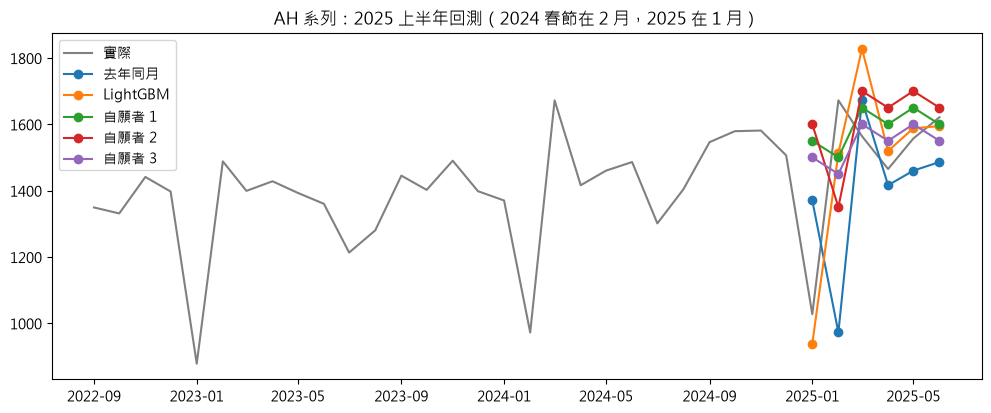

In [6]:
f = features(df)
m1 = train(f[f.month <= "2024-12-01"])
h = f[(f.month >= "2025-01-01") & (f.month <= "2025-06-01")].copy(); h["pred"] = forecast(m1, h)
ah = h[h["product"].str.startswith("AH")].groupby("month")[["qty", "lag12", "pred"]].sum()
res = {"去年同月": ah.lag12, "LightGBM": ah.pred}
for k, v in HAND.items(): res[k] = pd.Series(v, index=ah.index)
print("WAPE（越小越準）")
for k, v in res.items(): print("  %-8s %.1f%%" % (k, wape(ah.qty, v) * 100))
hist = f[f["product"].str.startswith("AH")].groupby("month").qty.sum()
plt.figure(figsize=(12, 4.5)); plt.plot(hist[hist.index <= "2025-06-01"], color="gray", label="實際")
for k, v in res.items(): plt.plot(v, marker="o", label=k)
plt.legend(); plt.title("AH 系列：2025 上半年回測（2024 春節在 2 月，2025 在 1 月）"); plt.show()

## 基礎模型 Chronos-Bolt（Colab 執行，第一次要下載模型）

In [ ]:
!pip -q install chronos-forecasting
import torch
from chronos import BaseChronosPipeline
pipe = BaseChronosPipeline.from_pretrained("amazon/chronos-bolt-small", device_map="cpu", torch_dtype=torch.float32)
ctx = torch.tensor(hist[hist.index <= "2024-12-01"].values, dtype=torch.float32)
q, mean = pipe.predict_quantiles(ctx, prediction_length=6, quantile_levels=[0.1, 0.5, 0.9])
chronos = pd.Series(q[0, :, 1].numpy(), index=ah.index)
print("Chronos-Bolt WAPE：%.1f%%" % (wape(ah.qty, chronos) * 100))

## 給生管：第四季預測與 AH-2101 十月的區間

In [7]:
keys = df[["series", "customer", "product"]].drop_duplicates()
fut = keys.merge(pd.DataFrame({"month": pd.date_range("2026-09-01", "2026-12-01", freq="MS")}), how="cross"); fut["qty"] = np.nan
g = features(pd.concat([df[["month", "series", "customer", "product", "qty"]], fut], ignore_index=True))
m2 = train(g[g.month <= "2026-08-01"])
q4 = g[g.month >= "2026-10-01"].copy(); q4["pred"] = forecast(m2, q4)
nb = q4[q4.customer == "C010"]
print("第四季 Northbridge 預測比去年同期多 %.0f%%" % ((nb.pred.sum() / nb.lag12.sum() - 1) * 100))
m3 = train(g[g.month <= "2025-08-01"])
bt = g[(g.month >= "2025-09-01") & (g.month <= "2026-08-01") & (g["product"] == "AH-2101")].copy(); bt["pred"] = forecast(m3, bt)
b = bt.groupby("month")[["qty", "pred"]].sum(); sigma = (b.qty - b.pred).std()
p50 = q4[(q4["product"] == "AH-2101") & (q4.month == "2026-10-01")].pred.sum()
print("AH-2101 十月：P50 約 %.0f 件，P90 約 %.0f 件（P90＝P50＋1.28 × 回測誤差標準差）" % (p50, p50 + 1.2816 * sigma))

第四季 Northbridge 預測比去年同期多 18%
AH-2101 十月：P50 約 1202 件，P90 約 1286 件（P90＝P50＋1.28 × 回測誤差標準差）
